### Utils

In [12]:
import time

import matplotlib.pyplot as plt
import numpy as np


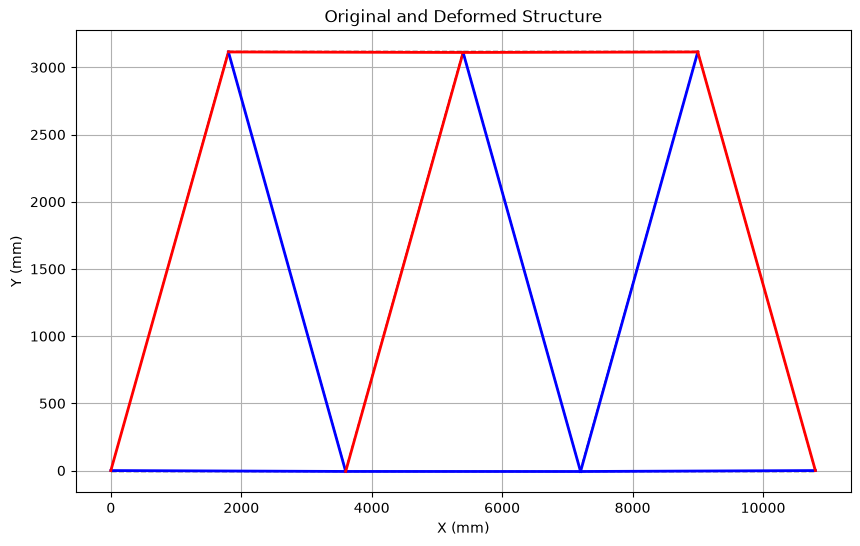

In [13]:
nodes = 7
before_coords = np.array([[0, 0], [3600,0], [7200, 0], [10800, 0], [1800, 3118], [5400, 3118], [9000, 3118]])
connections_elements = np.array([[0, 1], [1, 2], [2, 3], [0, 4], [1, 4], [1, 5], [2, 5], [2, 6], [3, 6], [4, 5], [5, 6]])
displacement = np.array([[0, 0], [0.74604, -6.5759], [2.3127, -6.9923],[3.1334, 0.0], [3.0836, -3.5033], [1.5916, -7.2363],  [-0.049736, -3.7330]])
after_coords = before_coords + displacement

stresses_elements = np.array([41.447, 87.038, 45.591, -82.900, 82.900, -8.2900, 8.2900, 91.189, -91.189, -82.893, -91.18])

# plotting the original and deformed structure
plt.figure(figsize=(10, 6))

# plot the original structure
for conn in connections_elements:
    plt.plot([before_coords[conn[0], 0], before_coords[conn[1], 0]], [before_coords[conn[0], 1], before_coords[conn[1], 1]], linewidth=1, color='black', linestyle='--')

# plot the deformed structure
for conn in connections_elements:
    if stresses_elements[np.where((connections_elements == conn).all(axis=1))[0][0]] > 0:
        plt.plot([after_coords[conn[0], 0], after_coords[conn[1], 0]], [after_coords[conn[0], 1], after_coords[conn[1], 1]], 'b-', linewidth=2)
    else:
        plt.plot([after_coords[conn[0], 0], after_coords[conn[1], 0]], [after_coords[conn[0], 1], after_coords[conn[1], 1]], 'r-', linewidth=2)

plt.xlabel('X (mm)')
plt.ylabel('Y (mm)')
plt.title('Original and Deformed Structure')
plt.grid(True)
plt.show()

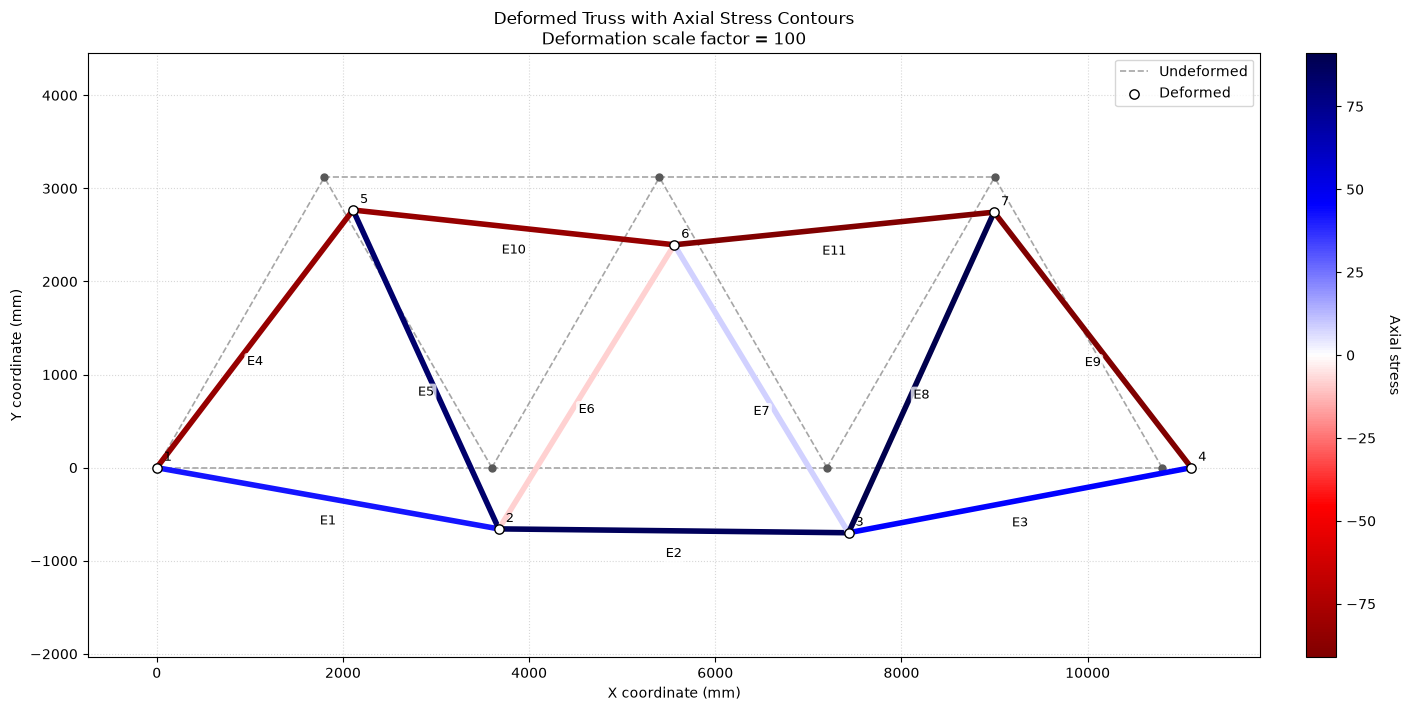

In [15]:
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable

# Amplification factor for displaying deformation
# The actual displacements are very small compared with the truss dimensions.
deformation_scale = 100

deformed_coords = before_coords + deformation_scale * displacement

# Create line segments for the deformed truss
segments = [
    [deformed_coords[i], deformed_coords[j]]
    for i, j in connections_elements
]

# Use a diverging colour map centered at zero stress
stress_limit = np.max(np.abs(stresses_elements))
norm = TwoSlopeNorm(
    vmin=-stress_limit,
    vcenter=0,
    vmax=stress_limit
)

fig, ax = plt.subplots(figsize=(14, 7), constrained_layout=True)

# Undeformed truss
for i, j in connections_elements:
    ax.plot(
        [before_coords[i, 0], before_coords[j, 0]],
        [before_coords[i, 1], before_coords[j, 1]],
        color="0.65",
        linestyle="--",
        linewidth=1.2,
        label="Undeformed" if i == 0 and j == 1 else None,
        zorder=1
    )

# Deformed truss coloured by stress
truss = LineCollection(
    segments,
    array=stresses_elements,
    cmap="seismic_r",
    norm=norm,
    linewidths=4,
    capstyle="round",
    zorder=3
)
ax.add_collection(truss)

# Nodes
ax.scatter(
    before_coords[:, 0],
    before_coords[:, 1],
    s=25,
    color="0.35",
    zorder=2
)

ax.scatter(
    deformed_coords[:, 0],
    deformed_coords[:, 1],
    s=45,
    facecolor="white",
    edgecolor="black",
    linewidth=1,
    zorder=4,
    label="Deformed"
)

# Node numbers
for node, (x, y) in enumerate(deformed_coords):
    ax.annotate(
        str(node + 1),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )
# Element numbers
for element_number, (i, j) in enumerate(connections_elements, start=1):
    midpoint = (deformed_coords[i] + deformed_coords[j]) / 2

    ax.annotate(
        f"E{element_number}",
        midpoint,
        xytext=(0, -12),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=9,
        color="black",
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            edgecolor="none",
            alpha=0.75
        ),
        zorder=5
    )
    
# Stress colour bar
scalar_map = ScalarMappable(norm=norm, cmap="seismic_r")
scalar_map.set_array(stresses_elements)

cbar = fig.colorbar(scalar_map, ax=ax, pad=0.02)
cbar.set_label("Axial stress", rotation=270, labelpad=18)

# Formatting
ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("X coordinate (mm)")
ax.set_ylabel("Y coordinate (mm)")
ax.set_title(
    f"Deformed Truss with Axial Stress Contours\n"
    f"Deformation scale factor = {deformation_scale:g}"
)

ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="best")
ax.margins(0.08)

plt.show()